# Figure S22 — Direct trace-element comparison with the B Trinity dacite vein

## 1. Imports and shared Science Advances setup

This section follows `00_Setup/Plotting_Setup.ipynb`. There are no custom functions. This figure contains measured compositions only; it does not calculate or plot binary-mixing trajectories.

In [1]:
from pathlib import Path
import hashlib
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.path import Path as MarkerPath
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
import numpy as np
import pandas as pd
from PIL import Image

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'

installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')

mpl.rcParams.update({
    'font.family':'sans-serif','font.sans-serif':[PUBLICATION_FONT],
    'font.size':BASE_TEXT_SIZE_PT,'axes.labelsize':BASE_TEXT_SIZE_PT,
    'axes.titlesize':BASE_TEXT_SIZE_PT,'xtick.labelsize':BASE_TEXT_SIZE_PT,
    'ytick.labelsize':BASE_TEXT_SIZE_PT,'legend.fontsize':BASE_TEXT_SIZE_PT,
    'legend.title_fontsize':BASE_TEXT_SIZE_PT,'figure.facecolor':'white',
    'axes.facecolor':'white','axes.grid':False,'axes.spines.top':True,
    'axes.spines.right':True,'axes.linewidth':0.5,'lines.linewidth':0.75,
    'xtick.direction':'in','ytick.direction':'in','xtick.major.width':0.5,
    'ytick.major.width':0.5,'xtick.minor.visible':False,
    'ytick.minor.visible':False,'savefig.dpi':EXPORT_DPI,
    'savefig.facecolor':'white','savefig.transparent':False,
    'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none',
})
print('Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.')

Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.


## 2. Figure S22 paths and plotting choices

Only the current S1 and S3 workbooks are used. The plotted points are measured melt inclusions, Kuehn distal glasses, B Trinity dacite-vein glass, and whole-rock compositions.

In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'SA_MI_Draft_FinalFigures_Work/DataSheets').is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from inside the Glacier Peak Efforts project.')

WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
CURRENT_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_S22_TE_Plots'
OUTPUT_DIRECTORY = CURRENT_DIRECTORY / 'Figure_S22_TE_Plots_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATA_DIRECTORY = WORK_ROOT / 'DataSheets' / 'Updated_Oct20'
S1_PATH = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx')
S3_PATH = DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx'
for path in [S1_PATH, S3_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f'Missing source workbook: {path}')
SOURCE_HASHES_BEFORE = {'S1': hashlib.sha256(S1_PATH.read_bytes()).hexdigest(), 'S3': hashlib.sha256(S3_PATH.read_bytes()).hexdigest()}

TRACE_ELEMENTS = ['Rb','Ba','Zr','Y','Nb','La','Ce','Nd','Th','Yb','Hf','Lu']
ALL_ELEMENTS = ['Sr', *TRACE_ELEMENTS]
ISOTOPE_BY_ELEMENT = {'Sr':'88Sr','Rb':'85Rb','Ba':'137Ba','Zr':'90Zr','Y':'89Y','Nb':'93Nb','La':'139La','Ce':'140Ce','Nd':'146Nd','Th':'232Th','Yb':'171Yb','Hf':'178Hf','Lu':'175Lu'}
SAMPLE_ORDER = ['74D','74A','75','76A']
SAMPLE_COLORS = {'74D':'#F4A261','74A':'#D55E00','75':'#56B4E9','76A':'#0072B2'}
SAMPLE_LABELS = {'74D':'B Middle','74A':'B Base','75':'G Top','76A':'G Middle'}
PHASE_ORDER = ['plag','pxy']
PHASE_MARKERS = {'plag':'o','pxy':'s'}
PHASE_LABELS = {'plag':'Plagioclase-hosted MI','pxy':'Pyroxene-hosted MI'}
KUEHN_COLORS = {'B':'#D4A017','G':'#006D77'}
KUEHN_MARKER_SPAN_PT = 6.9
KUEHN_HALF_ARM = (0.32 / 1.15) / 2
KUEHN_PLUS_VERTICES = np.array([[-KUEHN_HALF_ARM,-0.5],[KUEHN_HALF_ARM,-0.5],[KUEHN_HALF_ARM,-KUEHN_HALF_ARM],[0.5,-KUEHN_HALF_ARM],[0.5,KUEHN_HALF_ARM],[KUEHN_HALF_ARM,KUEHN_HALF_ARM],[KUEHN_HALF_ARM,0.5],[-KUEHN_HALF_ARM,0.5],[-KUEHN_HALF_ARM,KUEHN_HALF_ARM],[-0.5,KUEHN_HALF_ARM],[-0.5,-KUEHN_HALF_ARM],[-KUEHN_HALF_ARM,-KUEHN_HALF_ARM],[-KUEHN_HALF_ARM,-0.5]])
KUEHN_PLUS_PATH = MarkerPath(KUEHN_PLUS_VERTICES, closed=True)
DACITE_COLOR = '#9E2A4F'
print(f'Source S1: {S1_PATH}')
print(f'Source S3: {S3_PATH}')
print(f'Output directory: {OUTPUT_DIRECTORY}')

Source S1: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx
Source S3: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20/Dechert_S3_Compilations.xlsx
Output directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S22_TE_Plots/Figure_S22_TE_Plots_Final


## 3. Read and prepare the measured compositions

In [3]:
mi_source = pd.read_excel(S1_PATH, sheet_name='MI_Hosts_Plag_Pxy')
kuehn_source = pd.read_excel(S3_PATH, sheet_name='Kuehn2009')
vein_source = pd.read_excel(S1_PATH, sheet_name='Dacite_Vein')
whole_rock_source = pd.read_excel(S1_PATH, sheet_name='Whole_Rock')

mi = mi_source.copy()
mi['sample_key'] = mi['base_name'].astype('string').str.extract(r'^(74D|74A|75|76A)', expand=False)
mi['phase_key'] = mi['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx':'pxy'})
base_name_lower = mi['base_name'].astype('string').str.strip().str.casefold()
is_matrix_glass = base_name_lower.str.contains(r'(?:^|[_\s-])mtx(?:$|[_\s-])', regex=True, na=False) | base_name_lower.str.contains('matrix glass', regex=False, na=False) | mi['phase_key'].isin(['mtx','matrix','matrix glass','groundmass glass'])
mi = mi.loc[~is_matrix_glass & mi['sample_key'].isin(SAMPLE_ORDER) & mi['phase_key'].isin(PHASE_ORDER)].copy()
for element, isotope in ISOTOPE_BY_ELEMENT.items():
    mean_column = f'{isotope}_TE_MI_mean'
    std_column = f'{isotope}_TE_MI_std_1sigma'
    mi[element] = pd.to_numeric(mi[mean_column], errors='coerce') if mean_column in mi.columns else np.nan
    mi[f'{element}_std_1sigma'] = pd.to_numeric(mi[std_column], errors='coerce') if std_column in mi.columns else np.nan

kuehn = kuehn_source[['Analyzed Unit','Sample ID','Element',*ALL_ELEMENTS]].copy()
kuehn_text = kuehn['Analyzed Unit'].fillna('').astype(str) + ' | ' + kuehn['Sample ID'].fillna('').astype(str)
kuehn['Tephra'] = np.select([
    kuehn_text.str.contains(r'(?i)(?:\bbed\s*B(?:\b|[-\d])|(?:^|[/\s])B\d?\b)', regex=True),
    kuehn_text.str.contains(r'(?i)(?:\bbed\s*G(?:\b|-)|(?:^|[/\s])G\b)', regex=True),
], ['B','G'], default=pd.NA)
kuehn = kuehn.loc[kuehn['Tephra'].isin(['B','G'])].copy()

vein = vein_source.loc[vein_source['TE Sample'].notna()].copy()
for element, isotope in ISOTOPE_BY_ELEMENT.items():
    vein[element] = pd.to_numeric(vein_source.loc[vein.index, f'{isotope}_TE_ppm'], errors='coerce')

whole_rock = whole_rock_source.copy()
whole_rock['sample_key'] = whole_rock['Sample'].astype('string').str.replace('GP-','',regex=False)
for element in ALL_ELEMENTS:
    whole_rock[element] = pd.to_numeric(whole_rock_source.loc[whole_rock.index, f'{element}_ICPMS_ppm'], errors='coerce')

for frame in [mi, kuehn, vein, whole_rock]:
    for element in ALL_ELEMENTS:
        frame[element] = pd.to_numeric(frame[element], errors='coerce')

print(f'Melt inclusions retained: {len(mi)}')
print(f'Kuehn rows retained: {len(kuehn)}')
print(f'Dacite-vein rows retained: {len(vein)}')
print(f'Whole-rock rows retained: {len(whole_rock)}')

Melt inclusions retained: 199
Kuehn rows retained: 18
Dacite-vein rows retained: 20
Whole-rock rows retained: 4


## 4. Plot and export the direct comparison

No calculated mixing lines, model increments, endmembers, or mixing annotations are added.

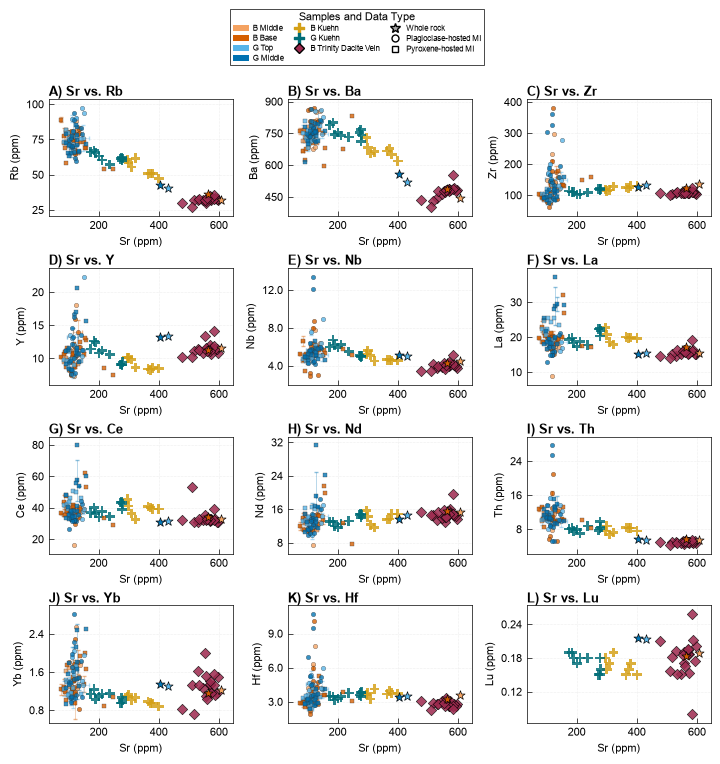

In [4]:
figure, axes = plt.subplots(4, 3, figsize=(DOUBLE_COLUMN_WIDTH_IN, MAXIMUM_RECOMMENDED_HEIGHT_IN))
axes = np.asarray(axes).ravel()
figure.subplots_adjust(left=0.075, right=0.988, bottom=0.065, top=0.865, wspace=0.30, hspace=0.44)

for panel_index, (axis, y_element) in enumerate(zip(axes, TRACE_ELEMENTS)):
    panel_label = chr(65 + panel_index)
    for tephra, color in KUEHN_COLORS.items():
        group = kuehn.loc[kuehn['Tephra'].eq(tephra)].dropna(subset=['Sr', y_element])
        axis.scatter(group['Sr'], group[y_element], marker=KUEHN_PLUS_PATH, color=color, s=KUEHN_MARKER_SPAN_PT**2, linewidths=0.0, edgecolors='none', alpha=0.84, zorder=2)

    for sample_key, color in SAMPLE_COLORS.items():
        for phase_key, marker in PHASE_MARKERS.items():
            group = mi.loc[mi['sample_key'].eq(sample_key) & mi['phase_key'].eq(phase_key)].dropna(subset=['Sr', y_element])
            if group.empty:
                continue
            x_error = group['Sr_std_1sigma']
            y_error = group[f'{y_element}_std_1sigma']
            if x_error.notna().any() or y_error.notna().any():
                axis.errorbar(group['Sr'], group[y_element], xerr=x_error if x_error.notna().any() else None, yerr=y_error if y_error.notna().any() else None, fmt='none', ecolor=color, elinewidth=0.42, capsize=1.1, alpha=0.46, zorder=2.4)
            axis.scatter(group['Sr'], group[y_element], marker=marker, facecolor=color, edgecolor='0.18', linewidths=0.26, s=10.5, alpha=0.78, zorder=3)

    group = vein.dropna(subset=['Sr', y_element])
    axis.scatter(group['Sr'], group[y_element], marker='D', facecolor=DACITE_COLOR, edgecolor='black', linewidths=0.45, s=28, alpha=0.86, zorder=4)

    for sample_key, color in SAMPLE_COLORS.items():
        group = whole_rock.loc[whole_rock['sample_key'].eq(sample_key)].dropna(subset=['Sr', y_element])
        axis.scatter(group['Sr'], group[y_element], marker='*', s=48, facecolor=color, edgecolor='black', linewidths=0.48, alpha=0.98, zorder=5)

    x_values = pd.concat([mi['Sr'], kuehn['Sr'], vein['Sr'], whole_rock['Sr']], ignore_index=True).dropna()
    y_values = pd.concat([mi[y_element], kuehn[y_element], vein[y_element], whole_rock[y_element]], ignore_index=True).dropna()
    x_padding = 0.075 * (x_values.max() - x_values.min())
    y_padding = 0.09 * (y_values.max() - y_values.min())
    axis.set_xlim(max(0, x_values.min() - x_padding), x_values.max() + x_padding)
    axis.set_ylim(max(0, y_values.min() - y_padding), y_values.max() + y_padding)
    axis.set_xlabel('Sr (ppm)')
    axis.set_ylabel(f'{y_element} (ppm)')
    axis.set_title(f'{panel_label}) Sr vs. {y_element}', loc='left', fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', pad=2)
    axis.grid(True, linestyle=':', linewidth=0.38, color='0.79', alpha=0.65)
    axis.set_axisbelow(True)
    axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
    axis.yaxis.set_major_locator(MaxNLocator(nbins=4))
    if y_element == 'Lu':
        axis.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    elif axis.get_ylim()[1] < 20:
        axis.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

sample_handles = [Patch(facecolor=SAMPLE_COLORS[key], edgecolor='none', label=SAMPLE_LABELS[key]) for key in SAMPLE_ORDER]
data_handles = [
    Line2D([], [], marker=KUEHN_PLUS_PATH, linestyle='none', color=KUEHN_COLORS['B'], markersize=KUEHN_MARKER_SPAN_PT, label='B Kuehn'),
    Line2D([], [], marker=KUEHN_PLUS_PATH, linestyle='none', color=KUEHN_COLORS['G'], markersize=KUEHN_MARKER_SPAN_PT, label='G Kuehn'),
    Line2D([], [], marker='D', linestyle='none', markerfacecolor=DACITE_COLOR, markeredgecolor='black', markersize=5, label='B Trinity Dacite Vein'),
    Line2D([], [], marker='*', linestyle='none', markerfacecolor='0.65', markeredgecolor='black', markersize=7, label='Whole rock'),
    Line2D([], [], marker='o', linestyle='none', markerfacecolor='white', markeredgecolor='black', markersize=5, label=PHASE_LABELS['plag']),
    Line2D([], [], marker='s', linestyle='none', markerfacecolor='white', markeredgecolor='black', markersize=5, label=PHASE_LABELS['pxy']),
]
legend = figure.legend(handles=sample_handles + data_handles, title='Samples and Data Type', loc='upper center', bbox_to_anchor=(0.5, 0.985), ncol=3, frameon=True, fancybox=False, facecolor='white', edgecolor='black', framealpha=1.0, fontsize=6.0, title_fontsize=BASE_TEXT_SIZE_PT, handletextpad=0.4, labelspacing=0.25, columnspacing=0.8, borderpad=0.35)
legend.get_frame().set_linewidth(0.5)

output_stem = OUTPUT_DIRECTORY / 'Figure_S22_Direct_Trace_Element_Comparison'
figure.savefig(output_stem.with_suffix('.pdf'), format='pdf', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(output_stem.with_suffix('.png'), format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(output_stem.with_suffix('.svg'), format='svg', dpi=EXPORT_DPI, facecolor='white', transparent=False)
plt.show()

## 5. Short output check

In [5]:
if len(mi) == 0 or len(kuehn) == 0 or len(vein) == 0 or len(whole_rock) != 4:
    raise ValueError('The established Figure S22 source populations changed.')
if len(axes) != 12:
    raise ValueError('Figure S22 must contain 12 panels.')
if any(line.get_label().startswith('_') is False and 'mixing' in line.get_label().casefold() for line in figure.axes[0].lines):
    raise ValueError('A calculated mixing line was added.')
for key, path in {'S1': S1_PATH, 'S3': S3_PATH}.items():
    if hashlib.sha256(path.read_bytes()).hexdigest() != SOURCE_HASHES_BEFORE[key]:
        raise RuntimeError(f'{key} source workbook changed during execution.')
for suffix in ['.png', '.pdf', '.svg']:
    if not (OUTPUT_DIRECTORY / f'Figure_S22_Direct_Trace_Element_Comparison{suffix}').is_file():
        raise FileNotFoundError(f'Missing Figure S22 export: {suffix}')
with Image.open(OUTPUT_DIRECTORY / 'Figure_S22_Direct_Trace_Element_Comparison.png') as image:
    if image.size != (2175, 2340):
        raise ValueError(f'Unexpected PNG dimensions: {image.size}')
print('Figure S22 check passed: direct measured comparison only; no mixing lines, increments, or endmembers.')

Figure S22 check passed: direct measured comparison only; no mixing lines, increments, or endmembers.
